# Experiment 6 - So sánh D-EHO và GA

- **Mục tiêu:** So sánh chất lượng nghiệm và hội tụ của hai solver độc lập trên cùng các bài TSP.
- **Cách thử:** 7 dataset × 5 seed × 2 thuật toán = tối đa 70 runs. Cùng mỗi cặp dataset/seed được chạy cho cả hai thuật toán.
- **Thông số:** Cả hai có tối đa 6.000 objective evaluations/run. EHO: 4 clan × 20 voi, `alpha=0.7`, `beta=0.3`. GA: population 80, tournament `k=3`, OX, inversion, crossover 0.9, mutation 0.15, 2 elites.
- **Kết quả:** Bảng báo cáo số runs, best, mean, median, worst và sample standard deviation theo thuật toán/dataset. Đường hội tụ dùng seed 11 trên dataset 48 thành phố, theo evaluation count.
- **Giới hạn:** Tổng thời gian tối đa 120 giây, mỗi run tối đa 10 giây; run cap có thể khiến một số cặp chưa hoàn tất. Chỉ so sánh nhóm có đủ dữ liệu tương ứng; best observed không đồng nghĩa optimum.
- **Chạy lại:** Chọn interpreter `.venv`, cài dependencies từ repo root, rồi chạy notebook.

In [1]:
from pathlib import Path
import html
import math
import statistics
import sys
from time import perf_counter

# Works from the repository root or when Jupyter starts in Experiment/.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir() and (ROOT.parent / "data").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import EHOConfig, GAConfig
from ga_eho_tsp.algorithms.eho import solve as solve_eho
from ga_eho_tsp.algorithms.ga import solve as solve_ga
from IPython.display import display, Markdown, SVG

MODE = "QUICK"
SEEDS = [11, 23, 37, 53, 71]
TOTAL_TIME_CAP_SECONDS = 120.0
PER_RUN_TIME_CAP_SECONDS = 10.0
NOTEBOOK_START = perf_counter()
RUN_COUNT = 0
MAX_RUNS = 70  # 7 datasets x 5 seeds x 2 algorithms.
RUN_RESULTS = []
RESULT_CACHE = {}

def show_table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "| " + " | ".join(["---"] * len(headers)) + " |\n"
    text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(text))

def run_with_caps(problem, algorithm, config, tag):
    """Run only within the declared notebook run/time caps; solver has its own cooperative cap."""
    global RUN_COUNT
    if tag in RESULT_CACHE:
        return RESULT_CACHE[tag]
    elapsed = perf_counter() - NOTEBOOK_START
    if RUN_COUNT >= MAX_RUNS or elapsed >= TOTAL_TIME_CAP_SECONDS:
        return None
    remaining = TOTAL_TIME_CAP_SECONDS - elapsed
    config = __import__("dataclasses").replace(
        config, time_limit_seconds=min(PER_RUN_TIME_CAP_SECONDS, remaining)
    )
    RUN_COUNT += 1
    result = algorithm(problem, config)
    assert result.is_valid
    if config.max_evaluations is not None:
        assert result.evaluations <= config.max_evaluations
    assert problem.route_length(result.best_route) == result.best_distance
    RUN_RESULTS.append((tag, result))
    RESULT_CACHE[tag] = result
    return result

def mean_std(values):
    if not values:
        return None, None
    return statistics.mean(values), (statistics.stdev(values) if len(values) > 1 else 0.0)

def plot_bars(title, labels, means, stds, ylabel="Best tour distance"):
    available = [(label, mean, std) for label, mean, std in zip(labels, means, stds)
                 if mean is not None and std is not None]
    if not available:
        display(Markdown(f"**{title}:** chưa có run hợp lệ trong giới hạn hiện tại. Restart kernel và chạy Run All để bắt đầu batch mới."))
        return
    labels, means, stds = zip(*available)
    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(max(7, len(labels) * 1.15), 4.5))
        ax.bar(range(len(labels)), means, yerr=stds, capsize=4, color="#4c8c78")
        ax.set_xticks(range(len(labels)), labels, rotation=25, ha="right")
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=.25)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    except ImportError:
        # SVG keeps the requested chart available in a notebook kernel without matplotlib.
        width, height = max(640, 90 * len(labels)), 390
        left, top, bottom = 55, 35, 105
        plot_h, plot_w = height - top - bottom, width - left - 20
        peak = max((m + s for m, s in zip(means, stds)), default=1) or 1
        pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
                  '<rect width="100%" height="100%" fill="white"/>',
                  f'<text x="{width/2}" y="22" text-anchor="middle" font-size="16">{html.escape(title)}</text>',
                  f'<line x1="{left}" y1="{top}" x2="{left}" y2="{height-bottom}" stroke="#333"/>',
                  f'<line x1="{left}" y1="{height-bottom}" x2="{width-15}" y2="{height-bottom}" stroke="#333"/>']
        slot = plot_w / max(1, len(labels)); bar_w = slot * .56
        for i, (label, mean, std) in enumerate(zip(labels, means, stds)):
            x = left + slot*i + (slot-bar_w)/2
            bar_h = mean / peak * plot_h
            y = height-bottom-bar_h
            mid = x + bar_w/2
            err = std / peak * plot_h
            pieces.extend([f'<rect x="{x:.1f}" y="{y:.1f}" width="{bar_w:.1f}" height="{bar_h:.1f}" fill="#4c8c78"/>',
                           f'<line x1="{mid:.1f}" y1="{y-err:.1f}" x2="{mid:.1f}" y2="{y+err:.1f}" stroke="#222" stroke-width="2"/>',
                           f'<line x1="{mid-6:.1f}" y1="{y-err:.1f}" x2="{mid+6:.1f}" y2="{y-err:.1f}" stroke="#222"/>',
                           f'<line x1="{mid-6:.1f}" y1="{y+err:.1f}" x2="{mid+6:.1f}" y2="{y+err:.1f}" stroke="#222"/>',
                           f'<text x="{mid:.1f}" y="{height-bottom+20}" text-anchor="middle" font-size="12">{html.escape(str(label))}</text>'])
        pieces.append('</svg>')
        display(SVG("".join(pieces)))


## Cấu hình và giới hạn chạy

Notebook dùng public API `EHOConfig` và `GAConfig`. Dataset paths được giải từ repo root hoặc thư mục `Experiment/`. Nếu chạm run/time cap, vòng lặp dừng và cell batch báo số lượt đã hoàn thành.

In [2]:
DATASET_FILES = ["03Cities-6.txt", "04Cities-189.txt", "06Cities-1248.txt", "15Cities-1194.txt",
                  "26Cities-937.txt", "42Cities-699.txt", "48Cities-33523.txt"]
DATASETS = [load_matrix(ROOT / "data" / filename) for filename in DATASET_FILES]
EVALUATION_BUDGET = 6000
MAX_RUNS = 70
EHO_BASE = EHOConfig(max_evaluations=EVALUATION_BUDGET, max_iterations=250, iterations=250,
                     clan_count=4, elephants_per_clan=20, alpha=0.7, beta=0.3)
GA_BASE = GAConfig(max_evaluations=EVALUATION_BUDGET, max_iterations=2000, generations=2000,
                   population_size=80, selection_method="tournament", tournament_size=3,
                   crossover_method="ox", crossover_rate=0.9, mutation_method="inversion",
                   mutation_rate=0.15, elite_count=2)
print(f"Datasets={len(DATASETS)}; seeds={SEEDS}; expected runs={MAX_RUNS}; budget={EVALUATION_BUDGET}; root={ROOT}")

Datasets=7; seeds=[11, 23, 37, 53, 71]; expected runs=70; budget=6000; root=D:\ga-eho-tsp


## Batch runs

Mỗi kết quả được lưu tạm trong notebook theo `(dataset, algorithm, seed)`. Sau mỗi lần solve, code kiểm tra route và tính lại objective để xác nhận distance. Không ghi kết quả mới vào source code.

In [3]:
results = {}
for problem in DATASETS:
    for algorithm_name, solver, base_config in (("EHO", solve_eho, EHO_BASE), ("GA", solve_ga, GA_BASE)):
        for seed in SEEDS:
            if RUN_COUNT >= MAX_RUNS or perf_counter() - NOTEBOOK_START >= TOTAL_TIME_CAP_SECONDS:
                break
            config = __import__("dataclasses").replace(base_config, seed=seed)
            result = run_with_caps(problem, solver, config, (problem.name, algorithm_name, seed))
            if result is None: break
            results[(problem.name, algorithm_name, seed)] = result
        if RUN_COUNT >= MAX_RUNS or perf_counter() - NOTEBOOK_START >= TOTAL_TIME_CAP_SECONDS: break
    if RUN_COUNT >= MAX_RUNS or perf_counter() - NOTEBOOK_START >= TOTAL_TIME_CAP_SECONDS: break
print(f"Runs completed: {RUN_COUNT}/{MAX_RUNS}; elapsed notebook time: {perf_counter()-NOTEBOOK_START:.2f}s")

Runs completed: 70/70; elapsed notebook time: 19.11s


## Bảng so sánh

`Best` và `worst` là distance thấp nhất/cao nhất trong các seed đã hoàn tất; mean, median và độ lệch chuẩn chỉ tính trên các run hoàn tất. Cột `runs` cho biết cỡ mẫu thực tế. Khi cap làm thiếu run, chỉ so sánh GA và EHO trên các nhóm dataset/seed tương ứng đã chạy đủ.

In [4]:
wide_rows = []
for problem in DATASETS:
    row = [problem.name]
    for algorithm_name in ("EHO", "GA"):
        runs = [results[(problem.name, algorithm_name, seed)] for seed in SEEDS
                if (problem.name, algorithm_name, seed) in results]
        if runs:
            mean, std = mean_std([r.best_distance for r in runs])
            row.extend((len(runs), min(r.best_distance for r in runs), round(mean, 3), round(statistics.median(r.best_distance for r in runs), 3), max(r.best_distance for r in runs), round(std, 3)))
        else:
            row.extend((0, "—", "—", "—", "—", "—"))
    wide_rows.append(tuple(row))
show_table(["dataset", "EHO runs", "EHO best", "EHO mean", "EHO median", "EHO worst", "EHO std", "GA runs", "GA best", "GA mean", "GA median", "GA worst", "GA std"], wide_rows)

| dataset | EHO runs | EHO best | EHO mean | EHO median | EHO worst | EHO std | GA runs | GA best | GA mean | GA median | GA worst | GA std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 03Cities-6 | 5 | 6.0 | 6.0 | 6.0 | 6.0 | 0.0 | 5 | 6.0 | 6.0 | 6.0 | 6.0 | 0.0 |
| 04Cities-189 | 5 | 189.0 | 189.0 | 189.0 | 189.0 | 0.0 | 5 | 189.0 | 189.0 | 189.0 | 189.0 | 0.0 |
| 06Cities-1248 | 5 | 1248.0 | 1248.0 | 1248.0 | 1248.0 | 0.0 | 5 | 1248.0 | 1248.0 | 1248.0 | 1248.0 | 0.0 |
| 15Cities-1194 | 5 | 1539.0 | 1668.8 | 1672.0 | 1796.0 | 90.965 | 5 | 1194.0 | 1200.2 | 1194.0 | 1225.0 | 13.864 |
| 26Cities-937 | 5 | 1509.0 | 1672.8 | 1693.0 | 1825.0 | 114.347 | 5 | 960.0 | 1056.4 | 1045.0 | 1148.0 | 72.844 |
| 42Cities-699 | 5 | 1961.0 | 2015.2 | 2003.0 | 2107.0 | 55.002 | 5 | 1137.0 | 1166.2 | 1163.0 | 1202.0 | 26.281 |
| 48Cities-33523 | 5 | 100054.0 | 103202.6 | 104397.0 | 104711.0 | 2035.519 | 5 | 47650.0 | 54194.4 | 54959.0 | 57933.0 | 3861.499 |

## Hội tụ trên bài 48 thành phố

Dùng lại kết quả seed 11 của hai thuật toán trong batch, không chạy thêm run. Trục ngang là objective evaluations, trục dọc là best-so-far distance. Nếu seed này chưa chạy trước khi chạm cap, biểu đồ được bỏ qua; code in thông báo trạng thái.

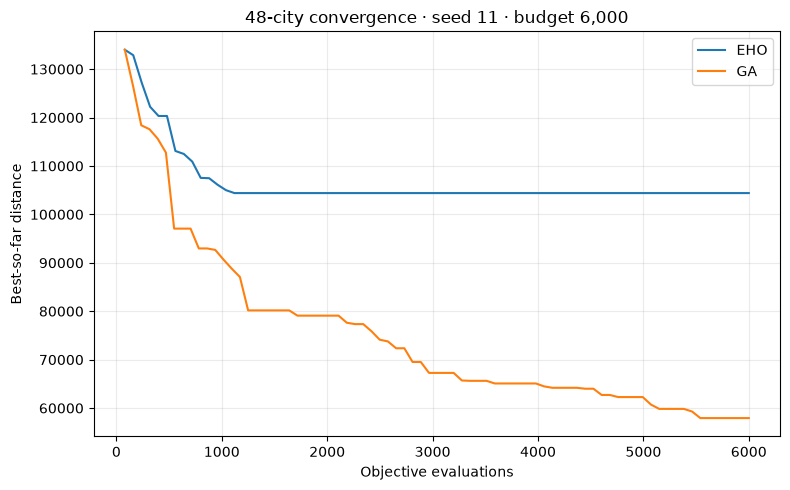

EHO: 104397 at 6000 evaluations; GA: 57933 at 6000 evaluations


In [5]:
CONVERGENCE_DATA = load_matrix(ROOT / "data" / "48Cities-33523.txt")
EHO_CONVERGENCE = results.get((CONVERGENCE_DATA.name, "EHO", 11))
GA_CONVERGENCE = results.get((CONVERGENCE_DATA.name, "GA", 11))
if EHO_CONVERGENCE is None or GA_CONVERGENCE is None:
    print("Convergence curve skipped: seed 11 / 48-city results were not reached before the run/time cap. Run All with the configured 120-second cap to include them.")
else:
    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8, 5))
        for label, result in (("EHO", EHO_CONVERGENCE), ("GA", GA_CONVERGENCE)):
            ax.plot([s.evaluations for s in result.history], [s.best_so_far for s in result.history], label=label)
        ax.set_xlabel("Objective evaluations")
        ax.set_ylabel("Best-so-far distance")
        ax.set_title("48-city convergence · seed 11 · budget 6,000")
        ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)
    except ImportError:
        rows = []
        for label, result in (("EHO", EHO_CONVERGENCE), ("GA", GA_CONVERGENCE)):
            rows.append((label, [(s.evaluations, s.best_so_far) for s in result.history]))
        show_table(["algorithm", "(evaluations, best-so-far) history"], rows)
    assert EHO_CONVERGENCE.is_valid and GA_CONVERGENCE.is_valid
    print(f"EHO: {EHO_CONVERGENCE.best_distance:g} at {EHO_CONVERGENCE.evaluations} evaluations; GA: {GA_CONVERGENCE.best_distance:g} at {GA_CONVERGENCE.evaluations} evaluations")